# Sentiment Analysis

This notebook studies the emotional tone of lyrics across genres. We derive a sentiment score for every song and use it to answer three main questions:

1. **Q1:** What are the predominant sentiments in each genre?
2. **Q2:** Has the sentiment of each genre changed over the years?
3. **Q3:** Is a song's sentiment related to its popularity (views), within and across genres?

We also look at three follow-up questions:

4. **Q4:** Which words drive positive and negative scores in each genre, and how much of rap's negativity is profanity?
5. **Q5:** Are choruses more positive than verses?
6. **Q6:** Does sentiment change from the beginning to the end of a song (emotional arc)?

Only the **training set** is used, because the test set has no genre labels.

## 1. Setup

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from scipy.stats import kruskal, mannwhitneyu, spearmanr, wilcoxon, pearsonr
from joblib import Parallel, delayed

project_root = os.path.abspath('..')
if project_root not in sys.path:
    sys.path.append(project_root)

import nltk
nltk.download('vader_lexicon', quiet=True)
from nltk.sentiment import SentimentIntensityAnalyzer

from utils.sentiment import score_song, split_lines, lexicon_word_counts, POS_THRESHOLD, NEG_THRESHOLD

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
GENRE_ORDER = ['country', 'misc', 'pop', 'rap', 'rb', 'rock']
PALETTE = dict(zip(GENRE_ORDER, sns.color_palette('Set2', 6)))

## 2. Method: line-level VADER

We use **VADER** (Hutto & Gilbert, 2014), a lexicon- and rule-based sentiment model. It needs no labelled data (we have no sentiment labels), and it handles negation ("not happy"), intensifiers ("very"), capitalisation and exclamation marks. This is why the sentiment text keeps stopwords, casing and punctuation, as decided in `Preprocessing.ipynb`.

VADER was designed for short texts such as tweets. Its compound score is a normalised sum of word valences, so on a full song (≈ 40 lines) the sum grows large and the score saturates near ±1. We therefore:
1. split the raw lyrics into lines and track the section each line belongs to (`[Chorus]`, `[Verse]`, ...);
2. score each line (lines with fewer than 2 words are skipped);
3. aggregate per song: **mean line compound** (main score), and the share of positive (≥ 0.05) and negative (≤ −0.05) lines.

The helper functions are in `utils/sentiment.py`. Scoring ~5M lines takes a few minutes in parallel, so the results are cached in `tmp/`.

In [2]:
df = pd.read_csv('../dataset/train.csv', usecols=['id', 'title', 'artist', 'year', 'views', 'lyrics', 'tag'])

cache_path = '../tmp/sentiment_scores.pickle'
if os.path.exists(cache_path):
    scores = pd.read_pickle(cache_path)
else:
    results = Parallel(n_jobs=-1, batch_size=256)(delayed(score_song)(l) for l in df['lyrics'])
    scores = pd.DataFrame(results, index=df.index)
    scores.to_pickle(cache_path)

df = df.join(scores)
df = df[df['n_lines'] > 0].copy()
df['sentiment'] = np.select(
    [df['mean_compound'] >= POS_THRESHOLD, df['mean_compound'] <= NEG_THRESHOLD],
    ['positive', 'negative'], default='neutral'
)
df['log_views'] = np.log1p(df['views'].clip(lower=0))
print(f"Scored songs: {len(df):,} | Total lines scored: {int(df['n_lines'].sum()):,}")

Scored songs: 134,966 | Total lines scored: 5,469,362


### 2.1 Why line-level scoring

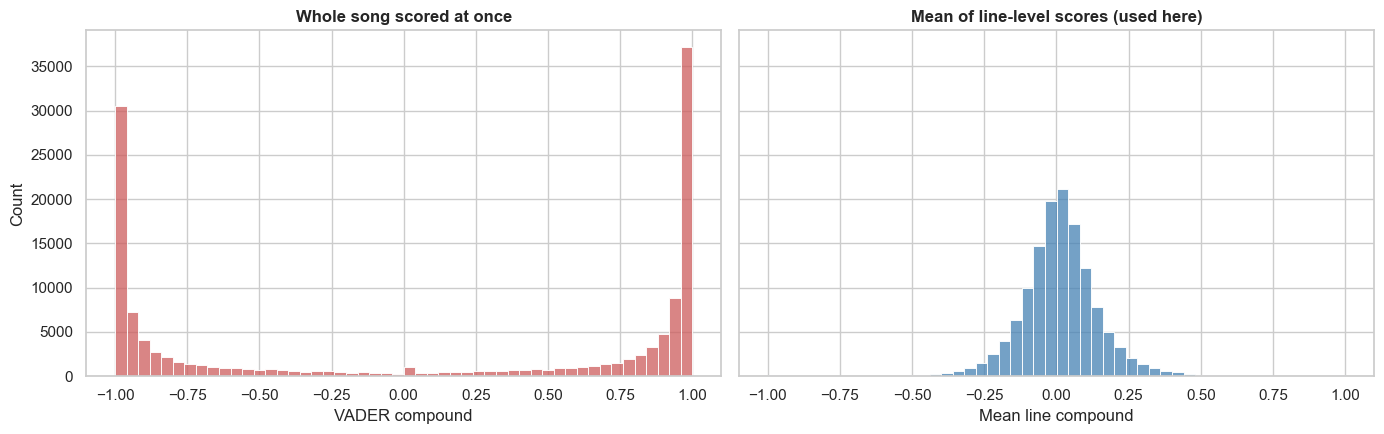

Songs with |compound| > 0.9 when scored whole: 65.7% vs. 0.3% with line-level scoring


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
sns.histplot(df['song_compound'], bins=50, ax=axes[0], color='indianred')
axes[0].set_title('Whole song scored at once', weight='bold')
axes[0].set_xlabel('VADER compound')
sns.histplot(df['mean_compound'], bins=50, ax=axes[1], color='steelblue')
axes[1].set_title('Mean of line-level scores (used here)', weight='bold')
axes[1].set_xlabel('Mean line compound')
plt.tight_layout()
plt.show()

sat = (df['song_compound'].abs() > 0.9).mean()
print(f"Songs with |compound| > 0.9 when scored whole: {sat:.1%} vs. {(df['mean_compound'].abs() > 0.9).mean():.1%} with line-level scoring")

Scored as a whole, about two thirds of the songs get a compound score beyond ±0.9, so most songs end up "extremely" positive or negative and genres cannot be told apart. Averaging line scores spreads the songs over a usable range: only 0.3% are beyond ±0.9.

### 2.2 Sanity check

Before analysing the scores, we check that they make sense by looking at the most positive and most negative songs with at least 15 scored lines.

In [4]:
pd.set_option('display.max_colwidth', 80)
eligible = df[df['n_lines'] >= 15]
cols = ['title', 'artist', 'tag', 'mean_compound', 'pos_share', 'neg_share']
print("Most positive songs:")
display(eligible.nlargest(5, 'mean_compound')[cols].round(3))
print("Most negative songs:")
display(eligible.nsmallest(5, 'mean_compound')[cols].round(3))

sia = SentimentIntensityAnalyzer()
examples = ["I love you baby, you make me feel so good",
            "I'm not happy without you",
            "Fuck the police",
            "We gon' kill it tonight, this beat is sick",
            "Tears on my guitar"]
display(pd.DataFrame({'Line': examples, 'Compound': [sia.polarity_scores(e)['compound'] for e in examples]}))

Most positive songs:


,title,artist,tag,mean_compound,pos_share,neg_share
72594,Utopia Chap. 6,Thomas More,misc,0.903,0.947,0.000
126476,Der Tourist - Supergeil EDEKA Version English Translation,Genius English Translations,pop,0.884,0.971,0.000
46329,Trash Art and the Movies VI,Pauline Kael,misc,0.831,0.933,0.067
109269,Considerations on Representative Government Chap. XVIII,John Stuart Mill,misc,0.808,0.889,0.037
45893,One of the Greats,Chelsea Peretti,misc,0.783,0.862,0.034


Most negative songs:


,title,artist,tag,mean_compound,pos_share,neg_share
59163,Psychedelic Reasons Fortold Elements,5series,rock,-0.859,0.000,1.000
61974,Oculus Infernum,Kult Ov Azazel,pop,-0.757,0.000,1.000
114071,Stop That Rape,Marc Rebillet,pop,-0.754,0.000,0.977
17012,Call Me Slut,Gimme Chocolat,rap,-0.715,0.032,0.871
2686,HAPPY GRINCHMAS,OCTOBERSFULLMOON,rap,-0.693,0.000,1.000


,Line,Compound
0,"I love you baby, you make me feel so good",0.8377
1,I'm not happy without you,-0.4585
2,Fuck the police,-0.5423
3,"We gon' kill it tonight, this beat is sick",-0.8402
4,Tears on my guitar,-0.2263


- The extremes are plausible: the most negative songs are dominated by violent or explicit lines, and the most positive are uplifting texts.
- They also show something about the data: several of the most positive "songs" in `misc` are **prose** (Thomas More's *Utopia*, John Stuart Mill), and one `pop` entry is a translation page. `misc` is partly a container for non-song texts, which matters when reading the `misc` results below.
- The example lines show the main weakness of a lexicon method on lyrics. Negation works ("not happy" → negative), but slang is read literally: "kill it" and "sick" are compliments in hip-hop and still score −0.84. We return to this in Section 6.1.

## 3. Q1: Predominant sentiment per genre

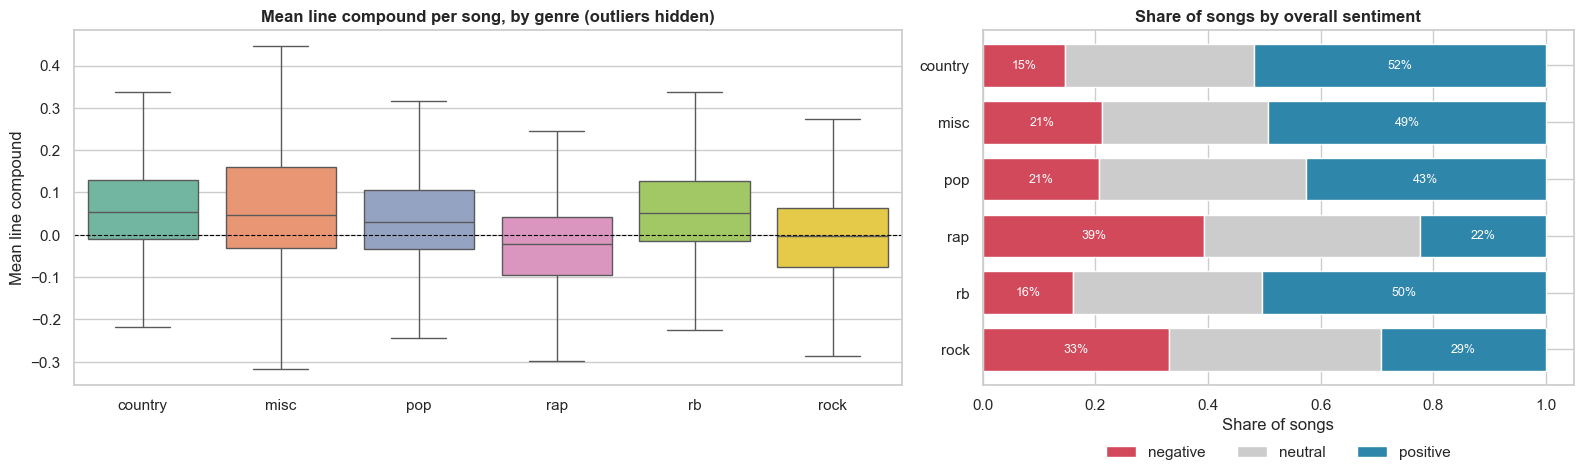

,songs,median_compound,mean_pos_line_share,mean_neg_line_share
tag,,,,
country,3466,0.055,0.297,0.181
misc,5639,0.048,0.349,0.231
pop,55742,0.031,0.264,0.196
rap,38584,-0.022,0.254,0.287
rb,6203,0.051,0.298,0.185
rock,25332,-0.004,0.226,0.239


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios': [1.4, 1]})

sns.boxplot(data=df, x='tag', y='mean_compound', order=GENRE_ORDER, hue='tag', palette=PALETTE,
            showfliers=False, ax=axes[0], legend=False)
axes[0].axhline(0, color='black', lw=0.8, ls='--')
axes[0].set_title('Mean line compound per song, by genre (outliers hidden)', weight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('Mean line compound')

shares = pd.crosstab(df['tag'], df['sentiment'], normalize='index').loc[GENRE_ORDER, ['negative', 'neutral', 'positive']]
shares.plot(kind='barh', stacked=True, ax=axes[1], color=['#d1495b', '#cccccc', '#2e86ab'], width=0.75)
for i, (g, row) in enumerate(shares.iterrows()):
    axes[1].text(row['negative'] / 2, i, f"{row['negative']:.0%}", va='center', ha='center', color='white', fontsize=9)
    axes[1].text(1 - row['positive'] / 2, i, f"{row['positive']:.0%}", va='center', ha='center', color='white', fontsize=9)
axes[1].invert_yaxis()
axes[1].set_title('Share of songs by overall sentiment', weight='bold')
axes[1].set_xlabel('Share of songs')
axes[1].set_ylabel('')
axes[1].legend(loc='lower center', bbox_to_anchor=(0.5, -0.25), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

summary = df.groupby('tag').agg(
    songs=('mean_compound', 'size'),
    median_compound=('mean_compound', 'median'),
    mean_pos_line_share=('pos_share', 'mean'),
    mean_neg_line_share=('neg_share', 'mean'),
).loc[GENRE_ORDER]
display(summary.round(3))

**Are the differences significant, and how large are they?** A Kruskal–Wallis test checks whether the genres share the same distribution of scores. With more than 130k songs almost any difference is "significant", so we also report an effect size for every pair of genres: the **rank-biserial correlation** $r = 2\cdot\frac{U}{n_1 n_2} - 1$ from the Mann–Whitney U test. It ranges from −1 to 1 and gives the probability that a random song from genre A scores higher than one from genre B, minus the reverse.

Kruskal-Wallis H = 8,912, p = 0.00e+00


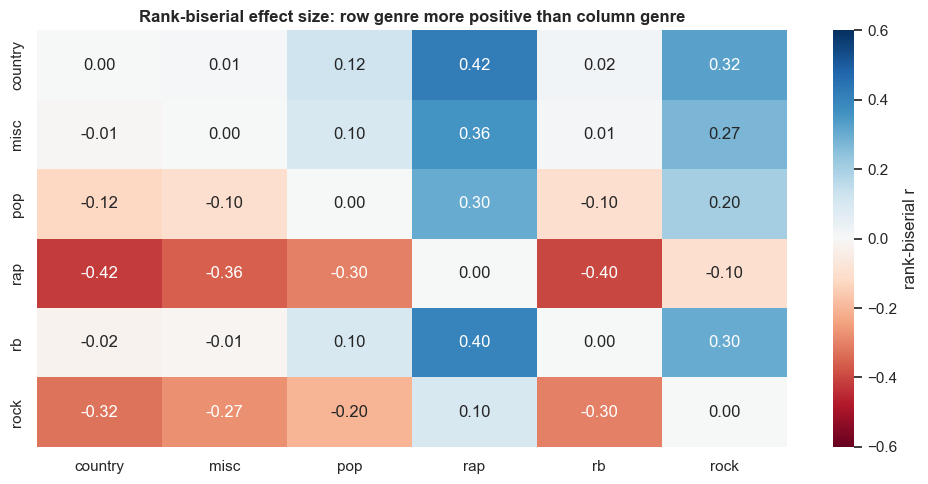

In [6]:
groups = [df.loc[df['tag'] == g, 'mean_compound'].values for g in GENRE_ORDER]
H, p = kruskal(*groups)
print(f"Kruskal-Wallis H = {H:,.0f}, p = {p:.2e}")

effect = pd.DataFrame(index=GENRE_ORDER, columns=GENRE_ORDER, dtype=float)
for i, a in enumerate(GENRE_ORDER):
    for j, b in enumerate(GENRE_ORDER):
        U, _ = mannwhitneyu(groups[i], groups[j], alternative='two-sided')
        effect.loc[a, b] = 2 * U / (len(groups[i]) * len(groups[j])) - 1

sns.heatmap(effect, annot=True, fmt='.2f', cmap='RdBu', center=0, vmin=-0.6, vmax=0.6, cbar_kws={'label': 'rank-biserial r'})
plt.title('Rank-biserial effect size: row genre more positive than column genre', weight='bold')
plt.tight_layout()
plt.show()

**Answer to Q1.**
- **Country, R&B and misc are the most positive genres**: about half of their songs are positive overall (country 52%, R&B 50%), and only 15–21% are negative.
- **Pop** is moderately positive (43% positive, 21% negative).
- **Rap is the only genre whose median is negative** (−0.022): 39% of rap songs are negative and only 22% positive.
- **Rock** is the most balanced (median ≈ 0; 33% negative vs. 29% positive).

The effect sizes show these are meaningful differences, not just statistical significance from a large sample. A random country or R&B song is more positive than a random rap song with rank-biserial r ≈ 0.4 (a medium-to-large effect), and than a rock song with r ≈ 0.3. Country, R&B and misc are practically indistinguishable from each other (|r| ≤ 0.02).

In short, the genres fall into two emotional groups: **love-centred genres (country, R&B, pop)** and **darker genres (rap, rock)**.

## 4. Q2: Sentiment over the years

Release years are grouped into 5-year bins from 1960 to 2024. Earlier years and invalid years (e.g. `year = 1`, found in the EDA) are excluded, and a genre-bin is shown only when it has at least 50 songs. Shaded bands are 95% confidence intervals of the mean. We also report the Spearman correlation between year and sentiment for each genre.

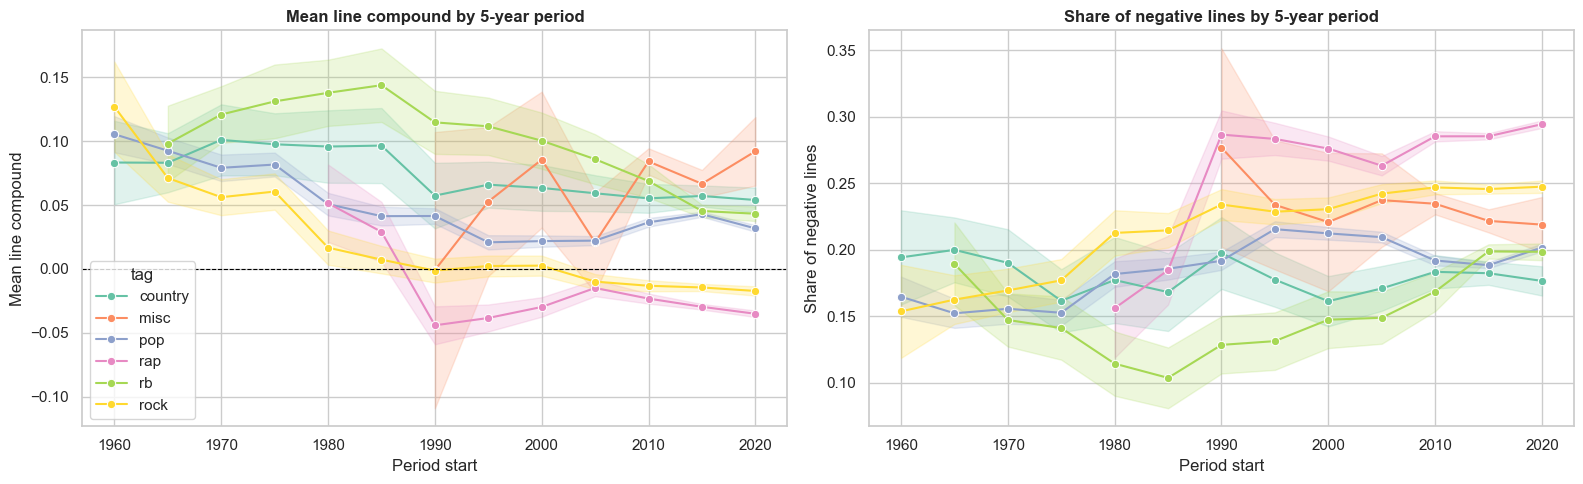

,Songs,Spearman rho (year vs. compound),p-value
Genre,,,
country,3335,-0.0900,0.0000
misc,4813,-0.0029,0.8383
pop,55372,-0.0151,0.0004
rap,38550,-0.0275,0.0000
rb,6151,-0.1601,0.0000
rock,25295,-0.0855,0.0000


Songs per period (all genres):
period
1960      557
1965     1131
1970     1237
1975     1397
1980     1607
1985     2146
1990     3375
1995     5529
2000     7723
2005    10365
2010    19620
2015    49713
2020    29116


In [7]:
years = df[df['year'].between(1960, 2024)].copy()
years['period'] = (years['year'] // 5) * 5

counts = years.groupby(['tag', 'period']).size()
valid = counts[counts >= 50].index
years_valid = years.set_index(['tag', 'period']).loc[lambda d: d.index.isin(valid)].reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.lineplot(data=years_valid, x='period', y='mean_compound', hue='tag', hue_order=GENRE_ORDER,
             palette=PALETTE, errorbar=('se', 1.96), marker='o', ax=axes[0])
axes[0].axhline(0, color='black', lw=0.8, ls='--')
axes[0].set_title('Mean line compound by 5-year period', weight='bold')
axes[0].set_xlabel('Period start')
axes[0].set_ylabel('Mean line compound')

sns.lineplot(data=years_valid, x='period', y='neg_share', hue='tag', hue_order=GENRE_ORDER,
             palette=PALETTE, errorbar=('se', 1.96), marker='o', ax=axes[1], legend=False)
axes[1].set_title('Share of negative lines by 5-year period', weight='bold')
axes[1].set_xlabel('Period start')
axes[1].set_ylabel('Share of negative lines')
plt.tight_layout()
plt.show()

trend = pd.DataFrame([
    {'Genre': g, 'Songs': len(sub), 'Spearman rho (year vs. compound)': spearmanr(sub['year'], sub['mean_compound'])[0],
     'p-value': spearmanr(sub['year'], sub['mean_compound'])[1]}
    for g, sub in years.groupby('tag')
]).set_index('Genre').loc[GENRE_ORDER]
display(trend.round(4))
print("Songs per period (all genres):")
print(years['period'].value_counts().sort_index().to_string())

**Answer to Q2.** Yes. Lyrics have become **less positive over time in almost every genre**:
- **R&B** shows the strongest decline (Spearman ρ = −0.16). It peaked in the mid-1980s (≈ 0.14) and fell to ≈ 0.04 in the 2020s, while its share of negative lines almost doubled (≈ 10% → 20%).
- **Rock** went from clearly positive in the 1960s (≈ 0.13) to slightly negative since 2005 (ρ = −0.09), with the share of negative lines rising from ≈ 15% to ≈ 25%.
- **Country** declines more gently (ρ = −0.09) and stays positive throughout.
- **Rap** turns negative when it becomes a large genre around 1990 and stays the most negative genre; its share of negative lines keeps growing (≈ 29% in the 2020s).
- **Pop** fell from ≈ 0.10 in the 1960s to ≈ 0.02–0.04 from the 1990s on, after which it is stable (ρ = −0.015).
- **misc** shows no trend (ρ ≈ 0, p = 0.84), which fits it being a mix of different text types.

Caveat: 74% of the songs are from 2010 or later, so the early periods are estimated from far fewer songs (wider confidence bands).

## 5. Q3: Sentiment and popularity

Popularity is measured by `log(1 + views)`. Views depend strongly on release year (newer songs on the platform collect more views), and sentiment also changes with year (Q2). To avoid this confounding, we compute a **partial Spearman correlation**: views and sentiment are converted to ranks, the mean rank within each 5-year period is subtracted, and the remaining ranks are correlated. The year effect is then removed from both variables.

,Songs,Spearman rho,Partial rho (| period),Partial p-value
Genre,,,,
country,3335,-0.0266,-0.0275,0.1120
misc,4813,-0.0581,-0.0451,0.0017
pop,55372,0.0714,0.0655,0.0000
rap,38550,-0.0423,-0.0554,0.0000
rb,6151,0.0434,0.0041,0.7501
rock,25295,0.0978,0.0753,0.0000
all genres,133516,0.0357,0.0156,0.0000


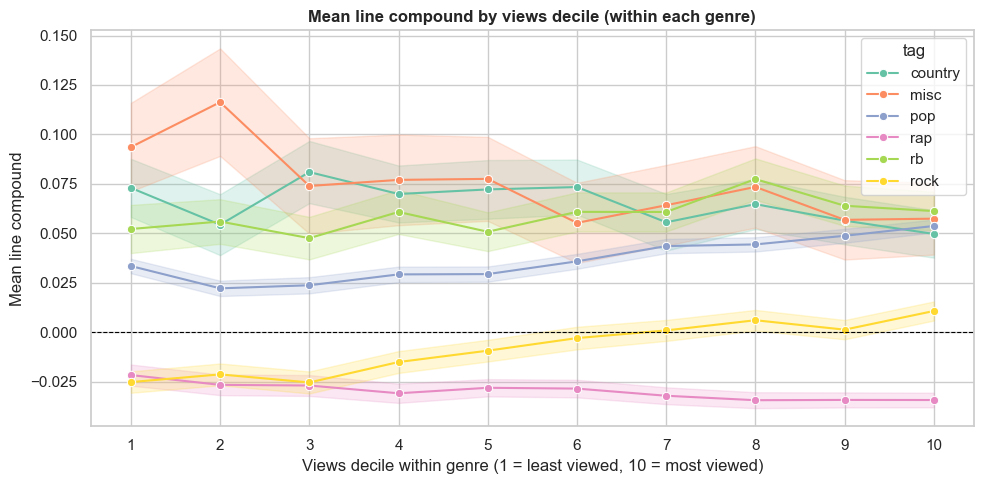

In [8]:
pop = years.copy()

def partial_spearman(sub, x, y, group='period'):
    rx = sub[x].rank()
    ry = sub[y].rank()
    rx = rx - rx.groupby(sub[group]).transform('mean')
    ry = ry - ry.groupby(sub[group]).transform('mean')
    return pearsonr(rx, ry)

rows = []
for g, sub in list(pop.groupby('tag')) + [('all genres', pop)]:
    rho, p = spearmanr(sub['log_views'], sub['mean_compound'])
    prho, pp = partial_spearman(sub, 'log_views', 'mean_compound')
    rows.append({'Genre': g, 'Songs': len(sub), 'Spearman rho': rho, 'Partial rho (| period)': prho, 'Partial p-value': pp})
pop_corr = pd.DataFrame(rows).set_index('Genre')
display(pop_corr.round(4))

pop['views_decile'] = pop.groupby('tag')['log_views'].transform(lambda s: pd.qcut(s.rank(method='first'), 10, labels=False) + 1)
sns.lineplot(data=pop, x='views_decile', y='mean_compound', hue='tag', hue_order=GENRE_ORDER,
             palette=PALETTE, errorbar=('se', 1.96), marker='o')
plt.axhline(0, color='black', lw=0.8, ls='--')
plt.title('Mean line compound by views decile (within each genre)', weight='bold')
plt.xlabel('Views decile within genre (1 = least viewed, 10 = most viewed)')
plt.ylabel('Mean line compound')
plt.xticks(range(1, 11))
plt.tight_layout()
plt.show()

**Answer to Q3.** Sentiment has **only a very weak relationship with popularity**. All correlations are below 0.08 in absolute value, so sentiment explains well under 1% of the variation in views. The *direction* differs by genre:
- In **rock** (partial ρ = 0.075) and **pop** (0.066), more-viewed songs are slightly more positive.
- In **rap** the opposite holds (−0.055): the more-viewed rap songs are slightly *more negative*. This may be because darker, more aggressive tracks are typical of the genre's most popular style.
- In **country** and **R&B**, there is no significant relationship once release period is controlled for (R&B's raw correlation of 0.043 disappears, so it was driven by year).

Across all genres the partial correlation is 0.016, so the sentiment of the lyrics is not a meaningful driver of popularity. The decile plot confirms this: the lines are almost flat compared with the gaps between genres.

## 6. Q4: Which words drive the sentiment?

For every genre we count how often each VADER lexicon word is used and multiply the count by the word's valence. Dividing by the genre's total number of lexicon-word occurrences gives each word's **share of the genre's sentiment mass**, so genres of different sizes are comparable. This shows *which* words make a genre score positive or negative.

In [9]:
lex = sia.lexicon
genre_counts = {g: Counter() for g in GENRE_ORDER}
for lyrics, g in zip(df['lyrics'], df['tag']):
    genre_counts[g].update(lexicon_word_counts(lyrics))

def top_contributors(counter, sign, n=10):
    total = sum(counter.values())
    contrib = {w: c * lex[w] / total for w, c in counter.items() if np.sign(lex[w]) == sign}
    return sorted(contrib.items(), key=lambda kv: -abs(kv[1]))[:n]

neg_table = pd.DataFrame({g: [f"{w} ({v:.3f})" for w, v in top_contributors(genre_counts[g], -1)] for g in GENRE_ORDER})
pos_table = pd.DataFrame({g: [f"{w} ({v:.3f})" for w, v in top_contributors(genre_counts[g], 1)] for g in GENRE_ORDER})
print("Top negative contributors (valence-weighted share):")
display(neg_table)
print("Top positive contributors (valence-weighted share):")
display(pos_table)

Top negative contributors (valence-weighted share):


,country,misc,pop,rap,rb,rock
0,no (-0.056),no (-0.048),no (-0.063),shit (-0.089),no (-0.076),no (-0.061)
1,hell (-0.022),death (-0.014),die (-0.017),bitch (-0.089),shit (-0.027),die (-0.028)
2,wrong (-0.017),dead (-0.013),bad (-0.016),fuck (-0.076),fuck (-0.025),dead (-0.027)
3,bad (-0.015),war (-0.010),wrong (-0.013),no (-0.060),bad (-0.020),hell (-0.019)
4,die (-0.015),poor (-0.008),dead (-0.013),niggas (-0.034),bitch (-0.014),death (-0.019)
5,cry (-0.013),bad (-0.008),pain (-0.013),bitches (-0.023),wrong (-0.012),pain (-0.017)
6,pain (-0.010),die (-0.008),hell (-0.012),ass (-0.021),die (-0.012),hate (-0.015)
7,lost (-0.010),fear (-0.006),cry (-0.011),bad (-0.019),pain (-0.012),kill (-0.014)
8,fire (-0.009),evil (-0.006),fuck (-0.011),die (-0.016),cry (-0.010),fuck (-0.014)
9,alone (-0.009),kill (-0.006),shit (-0.011),kill (-0.016),hate (-0.010),wrong (-0.013)


Top positive contributors (valence-weighted share):


,country,misc,pop,rap,rb,rock
0,love (0.206),like (0.049),love (0.201),like (0.137),love (0.274),love (0.112)
1,like (0.088),love (0.041),like (0.082),love (0.070),like (0.096),like (0.063)
2,good (0.044),great (0.036),yeah (0.040),yeah (0.061),yeah (0.091),yeah (0.026)
3,yeah (0.037),good (0.029),good (0.026),better (0.019),good (0.032),good (0.020)
4,well (0.026),hand (0.018),better (0.020),good (0.016),better (0.022),better (0.017)
5,best (0.020),well (0.018),best (0.016),best (0.016),best (0.017),free (0.016)
6,better (0.019),best (0.017),free (0.015),play (0.010),care (0.013),hand (0.014)
7,hand (0.018),better (0.012),hand (0.013),god (0.009),loving (0.012),best (0.014)
8,sweet (0.015),kind (0.011),care (0.012),care (0.009),want (0.011),well (0.014)
9,free (0.014),god (0.010),well (0.012),free (0.008),free (0.011),care (0.012)


### 6.1 Robustness check: how much of the negativity is profanity?

Profanity is common in rap, and VADER scores it as strongly negative, even though in rap it is often used for emphasis or bravado rather than negative emotion. To measure this, we remove a list of profanities and slurs from the lexicon and re-score a stratified sample of 2,000 songs per genre. If the gap between genres shrinks a lot, part of the measured negativity reflects word choice rather than emotional tone.

In [10]:
PROFANITY = ['fuck', 'fucking', 'fucked', 'fucker', 'fuckin', 'motherfucker', 'shit', 'shitty', 'bitch', 'bitches',
             'damn', 'damned', 'hell', 'ass', 'asshole', 'bastard', 'dick', 'piss', 'pissed', 'crap', 'whore', 'hoe']

sia_clean = SentimentIntensityAnalyzer()
for w in PROFANITY:
    sia_clean.lexicon.pop(w, None)

def mean_line_compound(lyrics, analyzer):
    comp = [analyzer.polarity_scores(l)['compound'] for l, _ in split_lines(lyrics)]
    return np.mean(comp) if comp else np.nan

sample = df.groupby('tag', group_keys=False).sample(n=2000, random_state=42)
sample['compound_no_profanity'] = [mean_line_compound(l, sia_clean) for l in sample['lyrics']]

robust = sample.groupby('tag')[['mean_compound', 'compound_no_profanity']].mean().loc[GENRE_ORDER]
robust['change'] = robust['compound_no_profanity'] - robust['mean_compound']
display(robust.round(4))

,mean_compound,compound_no_profanity,change
tag,,,
country,0.0668,0.0712,0.0044
misc,0.0805,0.0884,0.0079
pop,0.0387,0.0439,0.0052
rap,-0.0347,0.0179,0.0526
rb,0.0601,0.0712,0.0111
rock,-0.0044,0.0014,0.0058


**Answer to Q4.**
- **Positive sentiment is dominated by `love`** in every genre except rap and misc. In R&B, `love` alone accounts for 27% of the positive-weighted sentiment mass, and in country and pop about 20%.
- Negative sentiment differs in character between genres:
  - **Rock** and **misc** are driven by mortality and conflict (`die`, `dead`, `death`, `war`, `hate`, `kill`).
  - **Country** and **pop** by heartbreak (`wrong`, `cry`, `pain`, `alone`, `lost`).
  - **Rap** by profanity (`shit`, `bitch`, `fuck`).
- Two lexicon artefacts should be noted. `no` is the top negative contributor in almost every genre, although it is often just a filler ("no, no, no"). `like` is the second-largest positive contributor, although in lyrics it is mostly used as a comparison ("like a ...") rather than to express liking. In rap `like` is even the largest positive contributor (0.137).

**Profanity check.** Removing profanity from the lexicon changes the other genres by less than +0.011. Rap moves from **−0.035 to +0.018**, so **its negative average is almost entirely due to profanity**. Without profanity, rap is the second least positive genre (after rock) but no longer negative. The lyrics are aggressive in vocabulary more than in expressed emotion, which a lexicon method cannot fully separate.

## 7. Q5: Chorus vs. verse

For songs that have both `[Chorus]` (or `[Hook]`/`[Refrain]`) and `[Verse]` tags, we compare the mean sentiment of chorus lines with that of verse lines in the same song. Pairing within the song controls for each song's overall tone, and the Wilcoxon signed-rank test checks whether the median paired difference is zero.

,Songs with both,Mean chorus,Mean verse,Mean difference,Share chorus > verse,Wilcoxon p
Genre,,,,,,
country,1464,0.0631,0.0525,0.0106,0.5191,0.0720
misc,277,0.0119,-0.0015,0.0133,0.5271,0.2687
pop,13507,0.0521,0.0316,0.0204,0.5349,0.0000
rap,18067,-0.0236,-0.0329,0.0092,0.5232,0.0000
rb,3228,0.0680,0.0463,0.0218,0.5356,0.0000
rock,7678,0.0166,0.0005,0.0161,0.5284,0.0000


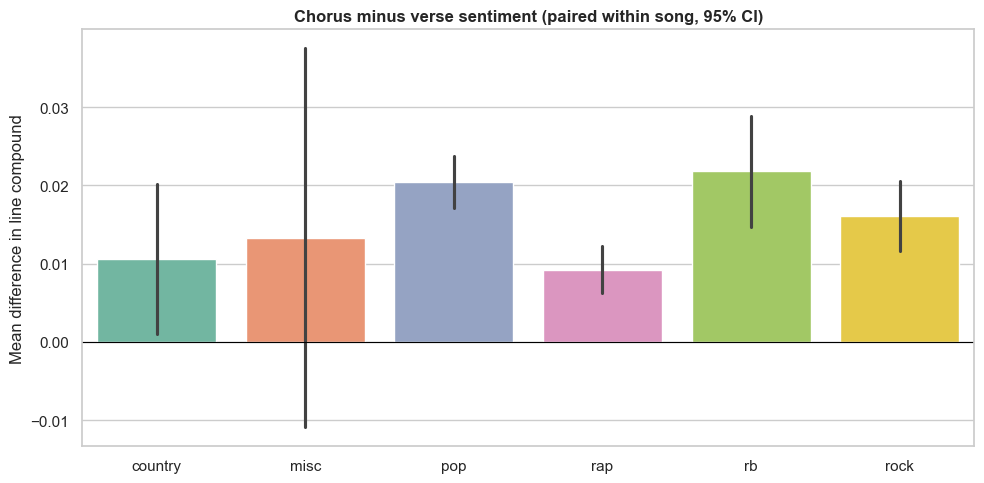

In [11]:
paired = df.dropna(subset=['chorus_compound', 'verse_compound']).copy()
paired['chorus_minus_verse'] = paired['chorus_compound'] - paired['verse_compound']

rows = []
for g in GENRE_ORDER:
    d = paired.loc[paired['tag'] == g, 'chorus_minus_verse']
    stat, p = wilcoxon(d)
    rows.append({'Genre': g, 'Songs with both': len(d), 'Mean chorus': paired.loc[paired['tag'] == g, 'chorus_compound'].mean(),
                 'Mean verse': paired.loc[paired['tag'] == g, 'verse_compound'].mean(),
                 'Mean difference': d.mean(), 'Share chorus > verse': (d > 0).mean(), 'Wilcoxon p': p})
chorus_df = pd.DataFrame(rows).set_index('Genre')
display(chorus_df.round(4))

sns.barplot(data=paired, x='tag', y='chorus_minus_verse', order=GENRE_ORDER, hue='tag', palette=PALETTE,
            errorbar=('se', 1.96), legend=False)
plt.axhline(0, color='black', lw=0.8)
plt.title('Chorus minus verse sentiment (paired within song, 95% CI)', weight='bold')
plt.xlabel('')
plt.ylabel('Mean difference in line compound')
plt.tight_layout()
plt.show()

**Answer to Q5.** In every genre, **choruses are slightly more positive than the verses of the same song**:
- The gap is largest in **R&B** (+0.022) and **pop** (+0.020), and in about 53–54% of their songs the chorus is the more positive part.
- The difference is significant for pop, rap, R&B and rock, but not for country (p = 0.07) or misc (p = 0.27).

This fits the role of the chorus as the uplifting, memorable hook, while verses carry the narrative, including its darker parts. The effect is small, though: a few hundredths on a −1 to 1 scale.

## 8. Q6: Emotional arc

We split each song's scored lines into thirds and compare the mean sentiment of the first and last thirds. A positive difference means the song ends more positively than it starts.

In [12]:
arc = df[df['n_lines'] >= 9].copy()
arc['end_minus_start'] = arc['last_third'] - arc['first_third']

rows = []
for g in GENRE_ORDER:
    d = arc.loc[arc['tag'] == g, 'end_minus_start']
    rows.append({'Genre': g, 'Songs': len(d), 'Mean first third': arc.loc[arc['tag'] == g, 'first_third'].mean(),
                 'Mean last third': arc.loc[arc['tag'] == g, 'last_third'].mean(),
                 'Mean difference': d.mean(), 'Wilcoxon p': wilcoxon(d)[1]})
arc_df = pd.DataFrame(rows).set_index('Genre')
display(arc_df.round(4))

,Songs,Mean first third,Mean last third,Mean difference,Wilcoxon p
Genre,,,,,
country,3416,0.0549,0.0713,0.0164,0.0000
misc,4508,0.0575,0.0644,0.0069,0.0630
pop,53757,0.0321,0.0454,0.0134,0.0000
rap,37239,-0.0281,-0.0260,0.0022,0.0004
rb,6045,0.0521,0.0692,0.0170,0.0000
rock,24382,-0.0114,-0.0020,0.0094,0.0000


**Answer to Q6.** Songs tend to **end slightly more positively than they start**. The last third scores higher than the first third in every genre:
- largest in **R&B** (+0.017), **country** (+0.016) and **pop** (+0.013);
- smaller in **rock** (+0.009);
- almost zero in **rap** (+0.002).

This is consistent with Q5: choruses usually repeat more towards the end of a song, so part of this arc is likely the chorus effect again rather than a narrative resolution.

## 9. Summary of Findings

| Question | Finding |
|---|---|
| Q1 – Predominant sentiment | Country, R&B and misc are clearly positive (≈ half of the songs positive); pop is moderately positive; rock is balanced; **rap is the only genre with a negative median**. Genre differences are medium-to-large (r up to 0.42). |
| Q2 – Over the years | Lyrics have become less positive over time, most strongly in R&B and rock; rap has been the most negative genre since it became large (~1990). |
| Q3 – Popularity | Sentiment barely relates to views (|partial ρ| < 0.08); slightly positive in pop and rock, slightly negative in rap. |
| Q4 – Driving words | `love` drives positivity; heartbreak words drive negativity in country and pop, death and conflict in rock, profanity in rap. Without profanity, rap's average turns slightly positive. |
| Q5 – Chorus vs. verse | Choruses are slightly more positive than verses, mainly in pop and R&B. |
| Q6 – Emotional arc | Songs end slightly more positively than they start, except rap. |

**Limitations.**
- VADER is a general-purpose lexicon. It reads slang literally ("kill it", "sick") and scores profanity as negative even when used as emphasis (Section 6.1).
- It counts filler words (`no`) and comparisons (`like`) as sentiment.
- It measures **polarity only**, not specific emotions (anger, sadness, joy). An emotion lexicon or a transformer model fine-tuned on emotion labels could give a finer picture.
- Repeated lines (choruses) are counted every time they appear. This reflects what the listener hears, but it gives choruses more weight.
- `misc` contains non-song texts (prose, translations), so its results do not describe a musical genre.
- Popularity is measured by platform views, which depend on when the song was added to the platform as well as on how popular it is.